In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


In [4]:
# Load CIFAR-10
(x_train_full, y_train_full), (x_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Training images:", x_train_full.shape)
print("Training labels:", y_train_full.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2431s 14us/step
Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Test images: (10000, 32, 32, 3)
Test labels: (10000, 1)


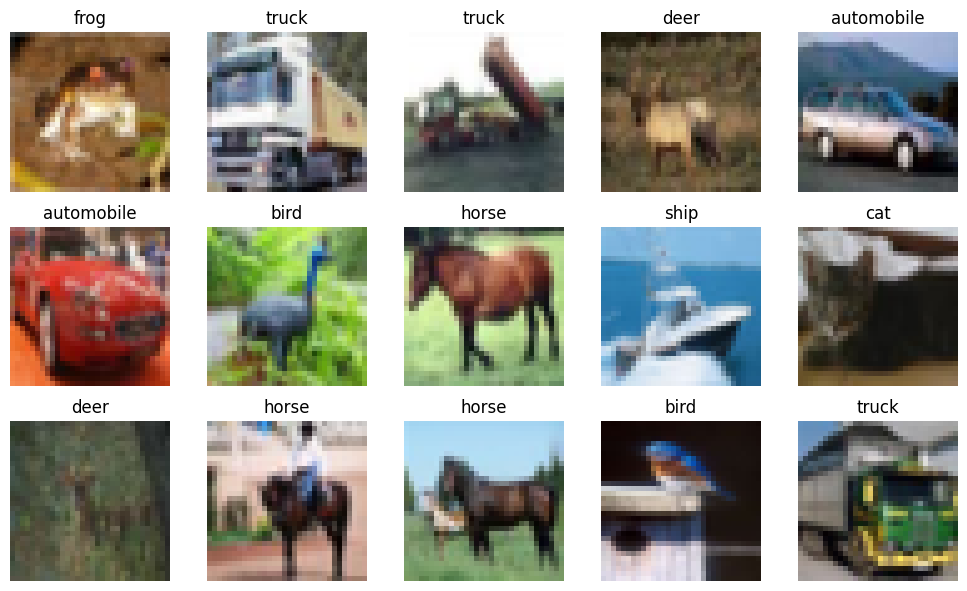

In [5]:
plt.figure(figsize=(10, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train_full[i])
    plt.title(class_names[int(y_train_full[i, 0])])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
# Convert pixel values from [0, 255] to [0, 1]
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Create training and validation sets
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.10,
    random_state=42,
    stratify=y_train_full.ravel()
)

print("Training set:", x_train.shape)
print("Validation set:", x_val.shape)
print("Test set:", x_test.shape)

Training set: (45000, 32, 32, 3)
Validation set: (5000, 32, 32, 3)
Test set: (10000, 32, 32, 3)


In [7]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(
        32, (3, 3), padding="same", activation="relu"
    ),
    tf.keras.layers.Conv2D(
        32, (3, 3), padding="same", activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3), padding="same", activation="relu"
    ),
    tf.keras.layers.Conv2D(
        64, (3, 3), padding="same", activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 591,274 (2.26 MB)

 Trainable params: 591,274 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
tf.keras.utils.plot_model(
    model,
    to_file="cnn_architecture.png",
    show_shapes=True,
    show_layer_names=True
)

You must install pydot (`pip install pydot`) for `plot_model` to work.


In [9]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 39ms/step - accuracy: 0.4066 - loss: 1.6143 - val_accuracy: 0.5568 - val_loss: 1.2270 - learning_rate: 0.0010
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 40ms/step - accuracy: 0.5736 - loss: 1.1956 - val_accuracy: 0.6628 - val_loss: 0.9560 - learning_rate: 0.0010
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 43s 42ms/step - accuracy: 0.6479 - loss: 1.0089 - val_accuracy: 0.6890 - val_loss: 0.8733 - learning_rate: 0.0010
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 43ms/step - accuracy: 0.6866 - loss: 0.8857 - val_accuracy: 0.7312 - val_loss: 0.7829 - learning_rate: 0.0010
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.7185 - loss: 0.8025 - val_accuracy: 0.7470 - val_loss: 0.7383 - learning_rate: 0.0010
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.7424 - loss: 0.7300 - val_accuracy: 0.7460 - val_loss: 0.7243 - learning_rate: 0.0010
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.7667 - l

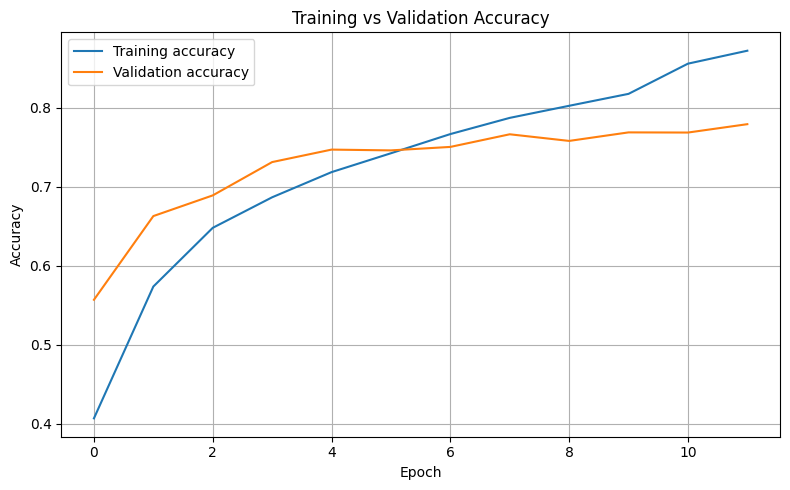

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("accuracy_curve.png", dpi=300)
plt.show()

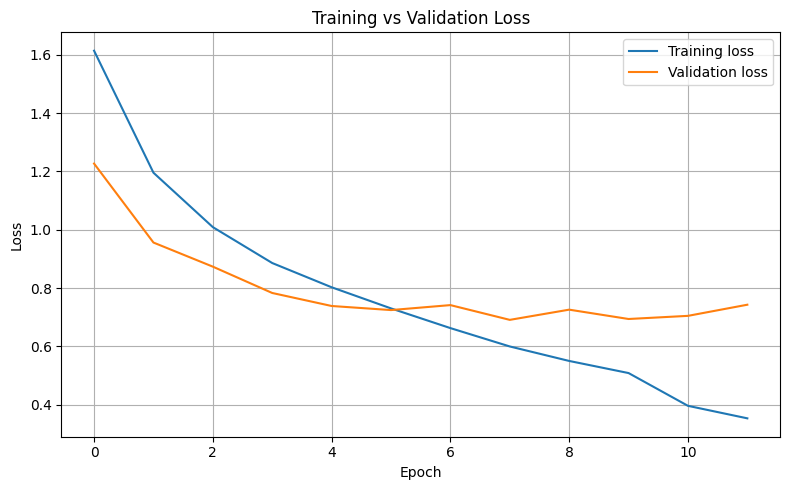

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=300)
plt.show()

In [12]:
test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy (%): {test_accuracy * 100:.2f}%")

Test loss: 0.7410
Test accuracy: 0.7514
Test accuracy (%): 75.14%


In [13]:
probabilities = model.predict(x_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)
y_true = y_test.ravel()

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(10),
    target_names=class_names,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

    airplane     0.7535    0.8010    0.7765      1000
  automobile     0.8284    0.8930    0.8595      1000
        bird     0.5873    0.6830    0.6315      1000
         cat     0.6388    0.4810    0.5488      1000
        deer     0.6944    0.7590    0.7253      1000
         dog     0.6733    0.6760    0.6747      1000
        frog     0.7758    0.8410    0.8071      1000
       horse     0.8103    0.7900    0.8000      1000
        ship     0.9109    0.7770    0.8386      1000
       truck     0.8704    0.8130    0.8407      1000

    accuracy                         0.7514     10000
   macro avg     0.7543    0.7514    0.7503     10000
weighted avg     0.7543    0.7514    0.7503     10000



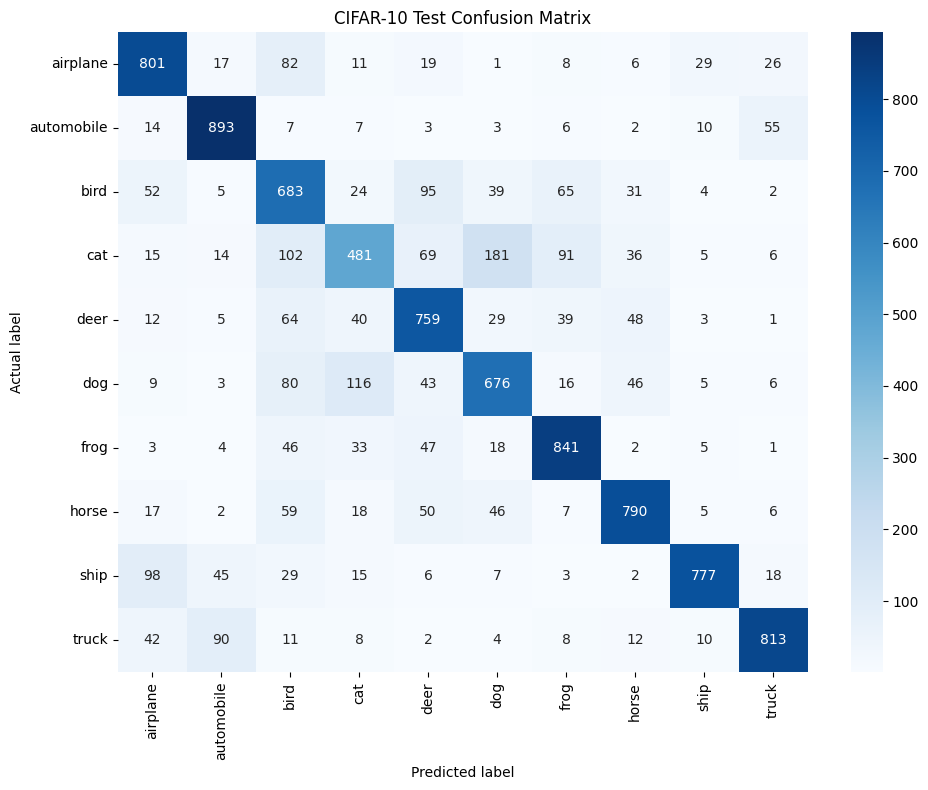

In [14]:
cm = confusion_matrix(
    y_true, y_pred, labels=np.arange(10)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("CIFAR-10 Test Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

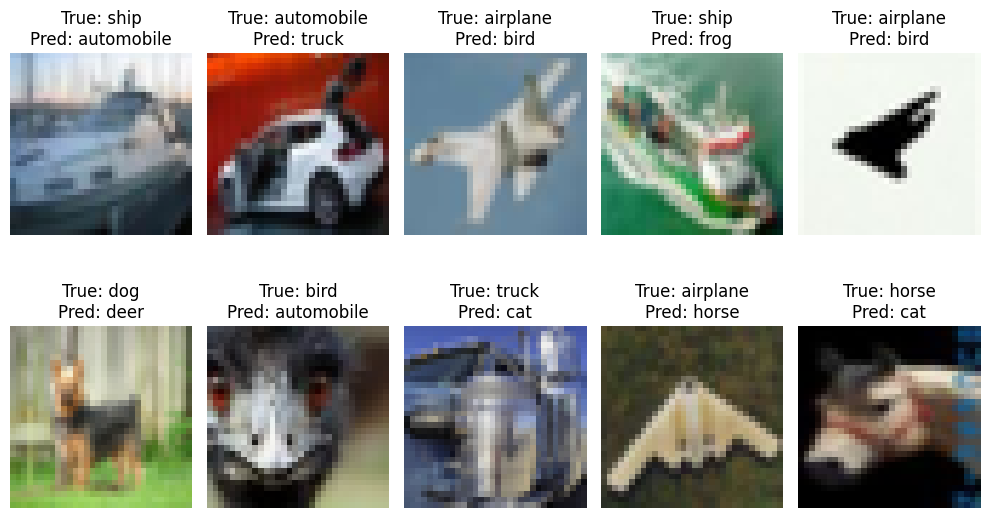

In [15]:
wrong = np.where(y_pred != y_true)[0]

plt.figure(figsize=(10, 6))

for j, idx in enumerate(wrong[:10]):
    plt.subplot(2, 5, j + 1)
    plt.imshow(x_test[idx])
    plt.title(
        f"True: {class_names[y_true[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.savefig("misclassified_examples.png", dpi=300)
plt.show()

In [16]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
])

# Insert after the Input layer in a revised model:
# augmentation,

In [17]:
# Save the model
model.save("cifar10_cnn.keras")

# Save evaluation metrics
with open("evaluation_results.txt", "w") as f:
    f.write(f"Test loss: {test_loss:.4f}\n")
    f.write(f"Test accuracy: {test_accuracy:.4f}\n")
    f.write("\n")
    f.write(classification_report(
        y_true,
        y_pred,
        labels=np.arange(10),
        target_names=class_names,
        zero_division=0
    ))

print("Model and evaluation results saved.")

Model and evaluation results saved.
